# M5 Retail Demand Forecasting — Notebook 4: Chronos-2 vs TFT vs LightGBM

**This notebook:** compare three different kinds of model on the same folds, the same rows and the same metrics, and choose one using pre-defined rules.

| Model | Type | Training |
|---|---|---|
| **LightGBM** (Notebook 3) | gradient-boosted trees with hand-built features | trained on our data |
| **Chronos-2** (Amazon) | pretrained time-series foundation model | **zero-shot**: no training on our data |
| **TFT** (Temporal Fusion Transformer) | attention-based deep-learning model | trained on our data (GPU) |

| | |
|---|---|
| **Inputs** | `m5_sample_long.parquet`, `feature_config.json`, `m5_series_stats.parquet`, `preds_lgbm_h28.parquet` |
| **Outputs** | `preds_all_models_h28.parquet`, `comparison_results_h28.json` |
| **Environment** | GPU recommended (Chronos-2 and TFT were run on a Kaggle GPU); internet access to download the Chronos-2 weights |

**Limitations that apply to the whole comparison**
1. **Possible pretraining overlap.** The Chronos-2 model card lists its training sources (a subset of Chronos Datasets, a subset of GIFT-Eval Pretrain, and synthetic data) but does not state whether M5 is included. If M5-like series were in pretraining, zero-shot scores could be optimistic. The comparison is therefore read as indicative, and the final holdout (Notebook 5) is used for the chosen model.
2. **Zero-shot versus trained.** Chronos-2 did not learn from our data; LightGBM and TFT did. A zero-shot model matching a trained one would be a strong result, the reverse much less so.
3. **Eligibility.** Chronos-2 and TFT need history. Series with fewer than 56 available days at the forecast origin (newly launched items) are excluded **for all models**, so every model is scored on identical rows (0.1% to 0.16% of rows dropped).
4. **One seed, one configuration** for TFT, with no extensive tuning.

---
## 1. Setup

The first cell installs `chronos-forecasting` and `neuralforecast` if they are missing. If the install changes the numpy or pandas version, restart the kernel and run the notebook again. We also check whether a GPU is available.

In [1]:
import importlib.util, subprocess, sys

need = {"chronos": "chronos-forecasting>=2.0", "neuralforecast": "neuralforecast"}
for mod, pkg in need.items():
    if importlib.util.find_spec(mod) is None:
        print("Installing", pkg, "...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
print("Done")

Installing chronos-forecasting>=2.0 ...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.8/80.8 kB 1.8 MB/s eta 0:00:00
Installing neuralforecast ...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 331.3/331.3 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.7/348.7 kB 14.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.4/50.4 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.5/87.5 kB 4.3 MB/s eta 0:00:00
Done


In [2]:
import json, time, warnings, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

try:
    import torch
    HAS_GPU = bool(torch.cuda.is_available())
except ImportError:
    torch, HAS_GPU = None, False
print("GPU available:", HAS_GPU, "|", torch.cuda.get_device_name(0) if HAS_GPU else "CPU only")

SEED = 42
H = 28
CONTEXT_DAYS = 730      # history shown to Chronos-2 (same as LightGBM's training window)
MIN_CONTEXT  = 56       # series with less history than this are excluded from the comparison
QLEVELS = [0.1, 0.5, 0.9]

def find_file(name):
    for root in [Path(".")] + ([Path("..")] if not Path("data").exists() else []) + [Path("/kaggle/working"), Path("/kaggle/input")]:
        if root.exists():
            hits = list(root.rglob(name))
            if hits:
                return hits[0]
    raise FileNotFoundError(f"{name} not found. Run Notebooks 1-3 first (on Kaggle, add their output as an input).")

LONG_PATH  = find_file("m5_sample_long.parquet")
CFG_PATH   = find_file("feature_config.json")
STATS_PATH = find_file("m5_series_stats.parquet")
PRED_PATH  = find_file("preds_lgbm_h28.parquet")
OUT = Path("/kaggle/working/processed") if Path("/kaggle/working").exists() else (Path("../data/processed") if (not Path("data").exists() and Path("../data").exists()) else Path("data/processed"))
OUT.mkdir(parents=True, exist_ok=True)
print("Files found. Output folder:", OUT)

GPU available: True | Tesla T4
Files found. Output folder: /kaggle/working/processed


---
## 2. Data preparation: wide matrix, folds and eligible series

As in the previous notebooks, sales are arranged in a matrix (dates x series) with `NaN` for unavailable days.

**Folds.** The same three windows as before. The **forecast origin is `train_end`**, and a single 28-day-ahead forecast is produced for the whole window, exactly the setting of the h = 28 LightGBM model.

**Covariates known in advance.** Calendar flags (weekend, SNAP, event, Christmas) and price. As for LightGBM, **price is assumed to be known in advance**; this is an assumption.

In [3]:
cfg = json.loads(CFG_PATH.read_text())
folds = [{"fold": f["fold"], "train_end": pd.Timestamp(f["train_end"]),
          "valid_start": pd.Timestamp(f["valid_start"]), "valid_end": pd.Timestamp(f["valid_end"])} for f in cfg["folds"]]
FOLD = {f["fold"]: f for f in folds}

raw = pd.read_parquet(LONG_PATH, columns=["id", "date", "store_id", "cat_id", "snap", "event_name_1", "event_type_1",
                                          "sell_price", "is_available", "sales"])
raw["date"] = pd.to_datetime(raw["date"])
raw["id"] = raw["id"].astype(str)
raw = raw.sort_values(["id", "date"]).reset_index(drop=True)

ids   = raw["id"].drop_duplicates().tolist()
dates = pd.DatetimeIndex(np.sort(raw["date"].unique()))
ni, nd = len(ids), len(dates)
assert len(raw) == ni * nd, "Incomplete panel"
assert (dates[-1] - dates[0]).days == nd - 1, "Dates are not daily-continuous"

def to_wide(values):
    return pd.DataFrame(np.asarray(values, dtype="float64").reshape(ni, nd).T, index=dates, columns=ids)

S = to_wide(raw["sales"].where(raw["is_available"]))     # NaN = unavailable
P = to_wide(raw["sell_price"])
Pf = P.ffill()                                           # price forward-fill (future price known-in-advance assumption)
meta = raw.drop_duplicates("id").set_index("id")[["store_id", "cat_id"]]

# ---- date-level calendar covariates ----
cal = raw.groupby("date").agg(snap=("snap", "max"), event_type=("event_type_1", "first"), event_name=("event_name_1", "first"))
cal["dow"] = "d" + cal.index.dayofweek.astype(str)                     # string => treated as categorical by Chronos
cal["is_weekend"] = (cal.index.dayofweek >= 5).astype("float32")
cal["dow_sin"] = np.sin(2 * np.pi * cal.index.dayofweek / 7).astype("float32")
cal["dow_cos"] = np.cos(2 * np.pi * cal.index.dayofweek / 7).astype("float32")
cal["snap"] = cal["snap"].astype("float32")
cal["has_event"] = cal["event_name"].notna().astype("float32")
cal["is_christmas"] = ((cal.index.month == 12) & (cal.index.day == 25)).astype("float32")
cal["event_type"] = cal["event_type"].fillna("none").astype(str)

# ---- eligible series per fold ----
ELIG = {}
for f in folds:
    cnt = S.loc[:f["train_end"]].notna().sum()
    ELIG[f["fold"]] = cnt[cnt >= MIN_CONTEXT].index.tolist()
    print(f"Fold {f['fold']}: origin={f['train_end'].date()} | eligible series: {len(ELIG[f['fold']])}/{ni}")

Fold 1: origin=2016-03-27 | eligible series: 998/999
Fold 2: origin=2016-02-28 | eligible series: 998/999
Fold 3: origin=2016-01-31 | eligible series: 997/999


In [4]:
# ---- saved predictions of LightGBM and the baselines (Notebook 3) ----
ev = pd.read_parquet(PRED_PATH)
ev["id"] = ev["id"].astype(str)
ev["date"] = pd.to_datetime(ev["date"])
n_total = ev.groupby("fold").size()
ev = ev[[i in set(ELIG[f]) for i, f in zip(ev["id"], ev["fold"])]].reset_index(drop=True)
n_kept = ev.groupby("fold").size()
print("Valid rows per fold (kept / total):")
print(pd.DataFrame({"kept": n_kept, "total": n_total, "dropped_%": (1 - n_kept / n_total) * 100}).round(2))

for c in ["chronos2_uni", "chronos2_cov", "tft"]:
    for suf in ["", "_q10", "_q50", "_q90"]:
        ev[c + suf] = np.nan
TIMING = {}
ev.head(3)

Valid rows per fold (kept / total):
       kept  total  dropped_%
fold                         
1     27944  27972     0.1000
2     27944  27972     0.1000
3     27916  27960     0.1600


,id,date,vol_tier,sales,fold,naive_lag28,moving_avg_28,same_weekday_mean,croston_sba,lgbm_default,lgbm_final,q10,q50,q90,chronos2_uni,chronos2_uni_q10,chronos2_uni_q50,chronos2_uni_q90,chronos2_cov,chronos2_cov_q10,chronos2_cov_q50,chronos2_cov_q90,tft,tft_q10,tft_q50,tft_q90
0,FOODS_1_008_CA_4_evaluation,2016-03-28,low,0.0000,1,0.0000,0.0714,0.0000,0.2260,0.1666,0.1249,0.0000,0.0000,0.8198,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,FOODS_1_008_CA_4_evaluation,2016-03-29,low,0.0000,1,2.0000,0.1429,0.5000,0.2237,0.2768,0.2540,0.0000,0.0000,0.9824,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,FOODS_1_008_CA_4_evaluation,2016-03-30,low,1.0000,1,1.0000,0.1786,0.2500,0.2373,0.2603,0.2146,0.0000,0.0000,0.9244,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


---
## 3. Metrics

The same metrics as in Notebook 3 are used (WAPE, MAE, bias, MASE, 7-day and 28-day-sum WAPE). They are now computed on the common set of eligible rows, so the LightGBM numbers differ very slightly from Notebook 3. The MASE scale again comes from the training period only.

In [5]:
def wape(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return float(np.abs(y - p).sum() / y.sum()) if y.sum() > 0 else float("nan")

def agg_wape(sub, y, p, days):
    blk = ((sub["date"] - sub["date"].min()).dt.days.to_numpy() // days)
    tmp = pd.DataFrame({"id": sub["id"].to_numpy(), "blk": blk, "y": y, "p": p})
    g = tmp.groupby(["id", "blk"])[["y", "p"]].sum()
    return float(np.abs(g["y"] - g["p"]).sum() / g["y"].sum())

_scale = {}
def mase_scale(fold):
    if fold not in _scale:
        D = (S - S.shift(H)).abs().loc[:FOLD[fold]["train_end"]]
        _scale[fold] = D.mean()
    return _scale[fold]

def evaluate(fold, col):
    sub = ev[(ev["fold"] == fold) & ev[col].notna()]
    if len(sub) == 0:
        return None
    y = sub["sales"].to_numpy(float); p = sub[col].to_numpy(float)
    sc = sub["id"].map(mase_scale(fold)).to_numpy(float); ok = sc > 0
    return {"rows": len(sub), "WAPE": wape(y, p), "MAE": float(np.abs(y - p).mean()),
            "bias_%": float((p.sum() - y.sum()) / y.sum() * 100),
            "MASE": float((np.abs(y - p)[ok] / sc[ok]).mean()),
            "WAPE_7d_sum": agg_wape(sub, y, p, 7), "WAPE_28d_sum": agg_wape(sub, y, p, 28)}

def summarize(models, fold_list=(1, 2, 3)):
    rows = []
    for m in models:
        res = {f: evaluate(f, m) for f in fold_list}
        res = {f: r for f, r in res.items() if r is not None}
        if not res:
            continue
        row = {"model": m, "n_folds": len(res)}
        for k in ["WAPE", "MAE", "bias_%", "MASE", "WAPE_7d_sum", "WAPE_28d_sum"]:
            row[k] = np.mean([r[k] for r in res.values()])
        for f in fold_list:
            row[f"WAPE_f{f}"] = res[f]["WAPE"] if f in res else np.nan
        rows.append(row)
    return pd.DataFrame(rows).set_index("model")

REF = ["naive_lag28", "moving_avg_28", "same_weekday_mean", "croston_sba", "lgbm_final"]
ref_tbl = summarize(REF)
print("Reference (common rows, 3-fold average):")
ref_tbl

Reference (common rows, 3-fold average):


,n_folds,WAPE,MAE,bias_%,MASE,WAPE_7d_sum,WAPE_28d_sum,WAPE_f1,WAPE_f2,WAPE_f3
model,,,,,,,,,,
naive_lag28,3,0.9505,1.3086,-1.8150,1.0804,0.4841,0.3034,0.9633,0.9621,0.9260
moving_avg_28,3,0.8081,1.1126,-4.2489,0.9530,0.4394,0.3215,0.8139,0.8260,0.7844
same_weekday_mean,3,0.8309,1.1440,-3.5217,0.9743,0.4332,0.3121,0.8330,0.8467,0.8131
croston_sba,3,0.8468,1.1658,-2.6741,1.0012,0.4704,0.3495,0.8465,0.8623,0.8314
lgbm_final,3,0.7656,1.0540,-4.3992,0.9350,0.3906,0.2775,0.7569,0.7839,0.7561


---
## 4. Chronos-2 (zero-shot)

**Foundation model.** Chronos-2 is pretrained on a very large and varied collection of time series. Given the history of a series (the *context*) it forecasts the future **without any weight update on our data**. This is called zero-shot or in-context forecasting.

**Two variants**

| Variant | Inputs |
|---|---|
| `chronos2_uni` | sales history only |
| `chronos2_cov` | sales history plus known-future covariates (weekday, SNAP, event, Christmas, price) |

**Input format (following the library's requirements).**
- long format with `id`, `timestamp`, `target` and covariate columns;
- regular daily timestamps without gaps: each series starts at its first available day, and pre-launch `NaN` rows are dropped;
- `future_df` contains exactly 28 rows per series, immediately after the context; its columns are the known-future covariates;
- boolean columns are treated as categorical by the library, so flags are passed as `float32`; `dow` and `event_type` are passed as strings, which the library treats as categorical variables.

**Output.** Point predictions (`predictions`) and the 0.1, 0.5 and 0.9 quantiles. We evaluate `predictions` and check its bias.

In [6]:
CHR_NUM = ["is_weekend", "snap", "has_event", "is_christmas"]     # float covariates
CHR_CAT = ["dow", "event_type"]                                   # string => categorical

def build_chronos_frames(fold, use_cov):
    f = FOLD[fold]; eids = ELIG[fold]
    cd = dates[(dates <= f["train_end"]) & (dates > f["train_end"] - pd.Timedelta(days=CONTEXT_DAYS))]
    fd = dates[(dates >= f["valid_start"]) & (dates <= f["valid_end"])]
    assert len(fd) == H, "validation window is not 28 days long"

    W = S.loc[cd, eids]
    n_c = len(cd); n_i = len(eids)
    ctx = pd.DataFrame({"id": np.repeat(np.array(eids, dtype=object), n_c),
                        "timestamp": np.tile(cd.to_numpy(), n_i),
                        "target": W.to_numpy(dtype="float32").T.ravel()})
    fut = pd.DataFrame({"id": np.repeat(np.array(eids, dtype=object), H),
                        "timestamp": np.tile(fd.to_numpy(), n_i)})
    if use_cov:
        for c in CHR_NUM + CHR_CAT:
            ctx[c] = np.tile(cal.loc[cd, c].to_numpy(), n_i)
            fut[c] = np.tile(cal.loc[fd, c].to_numpy(), n_i)
        ctx["sell_price"] = Pf.loc[cd, eids].to_numpy(dtype="float32").T.ravel()
        fut["sell_price"] = Pf.loc[fd, eids].to_numpy(dtype="float32").T.ravel()
    ctx = ctx[ctx["target"].notna()].reset_index(drop=True)     # drop the pre-launch days
    if use_cov:
        ctx["sell_price"] = ctx.groupby("id")["sell_price"].transform(lambda s: s.ffill().bfill())
        last_price = ctx.groupby("id")["sell_price"].last()
        fut["sell_price"] = fut["sell_price"].fillna(fut["id"].map(last_price))      # if the future price is missing, use the last known price
    return ctx, fut

ctx_demo, fut_demo = build_chronos_frames(1, use_cov=True)
print("context rows:", f"{len(ctx_demo):,}", "| future rows:", f"{len(fut_demo):,}")
print("Context length per series (min / median / max):", ctx_demo.groupby("id").size().agg(["min", "median", "max"]).tolist())
print("Columns:", ctx_demo.columns.tolist())
ctx_demo.head(3)

context rows: 702,150 | future rows: 27,944
Context length per series (min / median / max): [93.0, 730.0, 730.0]
Columns: ['id', 'timestamp', 'target', 'is_weekend', 'snap', 'has_event', 'is_christmas', 'dow', 'event_type', 'sell_price']


,id,timestamp,target,is_weekend,snap,has_event,is_christmas,dow,event_type,sell_price
0,FOODS_1_008_CA_4_evaluation,2014-03-29,0.0000,1.0000,0.0000,0.0000,0.0000,d5,none,3.2800
1,FOODS_1_008_CA_4_evaluation,2014-03-30,0.0000,1.0000,0.0000,0.0000,0.0000,d6,none,3.2800
2,FOODS_1_008_CA_4_evaluation,2014-03-31,1.0000,0.0000,0.0000,0.0000,0.0000,d0,none,3.2800


In [7]:
CHRONOS_OK = False
try:
    from chronos import Chronos2Pipeline
    t0 = time.time()
    pipeline = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map="cuda" if HAS_GPU else "cpu")
    print(f"Chronos-2 loaded in {time.time()-t0:.0f}s on {'GPU' if HAS_GPU else 'CPU'}")
    CHRONOS_OK = True
except Exception as e:
    print("Chronos-2 load FAIL:", type(e).__name__, str(e)[:400])
    print("-> Is internet access enabled (Kaggle: Settings) and is `chronos-forecasting` installed?")

config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  478MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Chronos-2 loaded in 6s on GPU


In [8]:
def run_chronos(name, use_cov, fold_list=(1, 2, 3)):
    for fold in fold_list:
        t0 = time.time()
        ctx, fut = build_chronos_frames(fold, use_cov)
        pred = pipeline.predict_df(
            ctx, future_df=fut if use_cov else None,
            id_column="id", timestamp_column="timestamp", target="target",
            prediction_length=H, quantile_levels=QLEVELS, freq="D",
        )
        pred = pred.rename(columns={"timestamp": "date"})
        pred["id"] = pred["id"].astype(str)
        pred["date"] = pd.to_datetime(pred["date"])
        cols_map = {"predictions": name, "0.1": name + "_q10", "0.5": name + "_q50", "0.9": name + "_q90"}
        pred = pred.rename(columns=cols_map)
        for c in cols_map.values():
            pred[c] = pred[c].clip(lower=0)

        sub = ev.loc[ev["fold"] == fold, ["id", "date"]]
        m = sub.merge(pred[["id", "date"] + list(cols_map.values())], on=["id", "date"], how="left", validate="one_to_one")
        assert m[name].notna().all(), f"{name} fold {fold}: some rows have no prediction"
        ev.loc[sub.index, list(cols_map.values())] = m[list(cols_map.values())].to_numpy()
        TIMING[(name, fold)] = time.time() - t0
        r = evaluate(fold, name)
        print(f"[{name}] fold {fold}: WAPE={r['WAPE']:.4f} | 7d={r['WAPE_7d_sum']:.4f} | bias={r['bias_%']:+.1f}% | {TIMING[(name, fold)]:.0f}s")

CHRONOS_ERR = None
if CHRONOS_OK:
    try:
        run_chronos("chronos2_uni", use_cov=False)
        run_chronos("chronos2_cov", use_cov=True)
    except Exception as e:
        CHRONOS_ERR = f"{type(e).__name__}: {str(e)[:600]}"
        print("Chronos run FAIL:", CHRONOS_ERR)

[chronos2_uni] fold 1: WAPE=0.7011 | 7d=0.4570 | bias=-30.5% | 6s
[chronos2_uni] fold 2: WAPE=0.7282 | 7d=0.4935 | bias=-32.0% | 4s
[chronos2_uni] fold 3: WAPE=0.7068 | 7d=0.4715 | bias=-31.0% | 4s
[chronos2_cov] fold 1: WAPE=0.7124 | 7d=0.4699 | bias=-29.8% | 34s
[chronos2_cov] fold 2: WAPE=0.7164 | 7d=0.4800 | bias=-28.6% | 36s
[chronos2_cov] fold 3: WAPE=0.7232 | 7d=0.4880 | bias=-28.2% | 39s


**Result.** Chronos-2 reaches a daily WAPE of 0.712 (univariate) and 0.717 (with covariates), better than LightGBM (0.766), but its total-demand bias is -31% and -29%. The covariates did not help: the covariate variant is slightly worse and its interval coverage drops from 77.6% to 72.9%.

---
## 5. TFT (Temporal Fusion Transformer)

TFT is a deep-learning forecaster that treats three kinds of input separately:

| Input | In our data |
|---|---|
| **Static** (fixed properties of a series) | store, category, log mean sales, share of zero days |
| **Known future** | weekend, day-of-week sine/cosine, SNAP, event, Christmas, relative price |
| **Observed past** | past sales |

It combines recurrent layers with attention and produces the whole 28-day forecast at once (direct approach, like our LightGBM).

**Setup**
- **Loss:** Tweedie distribution loss, consistent with LightGBM. A short smoke test (80 training steps on 120 series) checks that the loss is numerically stable and that the forecasts are finite, positive and not constant. If it fails we fall back to a negative-binomial loss and finally to a quantile loss.
- **Training window:** the last 730 days before `train_end`; no validation-based early stopping.
- **Scaler:** `standard`. The default `robust` scaler uses the median, which is 0 for most intermittent series (a design choice; not compared experimentally).
- **`devices=1`:** NeuralForecast uses all GPUs by default, which can fail on multi-GPU notebooks, so one GPU is forced.
- Static features come from the training data only; the random seed is fixed.
- Static and future covariates are numeric (one-hot / sine-cosine encodings).

In [9]:
TFT_FOLDS      = (1, 2, 3)      # use (1,) to save time
TFT_MAX_STEPS  = 1500
TFT_INPUT      = 112            # 16-week history window
TFT_HIDDEN     = 64
TFT_TRAIN_DAYS = 730
TFT_RHO        = 1.3            # Tweedie variance power (also selected by the LightGBM tuning)
RUN_TFT        = HAS_GPU        # TFT is very slow on CPU; set to True to force it

FUTR = ["is_weekend", "dow_sin", "dow_cos", "snap", "has_event", "is_christmas", "price_rel"]
STORES = sorted(meta["store_id"].unique()); CATS = sorted(meta["cat_id"].unique())
STAT = [f"store_{s}" for s in STORES] + [f"cat_{c}" for c in CATS] + ["log_mean", "zero_share"]

def build_tft_frames(fold, id_list):
    f = FOLD[fold]
    td = dates[(dates <= f["train_end"]) & (dates > f["train_end"] - pd.Timedelta(days=TFT_TRAIN_DAYS))]
    fd = dates[(dates >= f["valid_start"]) & (dates <= f["valid_end"])]
    W = S.loc[td, id_list]
    base_price = P.loc[:f["train_end"], id_list].median().fillna(1.0).replace(0, 1.0)
    Prel = (Pf[id_list] / base_price).astype("float32")
    n_t, n_i = len(td), len(id_list)

    tr = pd.DataFrame({"unique_id": np.repeat(np.array(id_list, dtype=object), n_t),
                       "ds": np.tile(td.to_numpy(), n_i),
                       "y": W.to_numpy(dtype="float32").T.ravel()})
    for c in FUTR[:-1]:
        tr[c] = np.tile(cal.loc[td, c].to_numpy(dtype="float32"), n_i)
    tr["price_rel"] = Prel.loc[td].to_numpy(dtype="float32").T.ravel()
    tr = tr[tr["y"].notna()].reset_index(drop=True)                       # drop the pre-launch days
    tr["price_rel"] = tr.groupby("unique_id")["price_rel"].transform(lambda s: s.ffill().bfill()).fillna(1.0)

    fu = pd.DataFrame({"unique_id": np.repeat(np.array(id_list, dtype=object), H), "ds": np.tile(fd.to_numpy(), n_i)})
    for c in FUTR[:-1]:
        fu[c] = np.tile(cal.loc[fd, c].to_numpy(dtype="float32"), n_i)
    fu["price_rel"] = Prel.loc[fd].to_numpy(dtype="float32").T.ravel()
    fu["price_rel"] = fu["price_rel"].fillna(fu["unique_id"].map(tr.groupby("unique_id")["price_rel"].last())).fillna(1.0)

    st = pd.DataFrame({"unique_id": id_list})
    for s in STORES: st[f"store_{s}"] = (meta.loc[id_list, "store_id"].to_numpy() == s).astype("float32")
    for c in CATS:   st[f"cat_{c}"]   = (meta.loc[id_list, "cat_id"].to_numpy() == c).astype("float32")
    st["log_mean"] = np.log1p(W.mean().reindex(id_list).fillna(0).to_numpy()).astype("float32")
    st["zero_share"] = (W.eq(0).sum() / W.notna().sum().replace(0, np.nan)).reindex(id_list).fillna(0).to_numpy().astype("float32")
    return tr, fu, st

tr_demo, fu_demo, st_demo = build_tft_frames(1, ELIG[1][:50])
print("train:", tr_demo.shape, "| futr:", fu_demo.shape, "| static:", st_demo.shape)
assert fu_demo.groupby("unique_id").size().eq(H).all()
assert not tr_demo[FUTR + ["y"]].isna().any().any(), "NaN in the training frame"
tr_demo.head(3)

train: (35842, 10) | futr: (1400, 9) | static: (50, 10)


,unique_id,ds,y,is_weekend,dow_sin,dow_cos,snap,has_event,is_christmas,price_rel
0,FOODS_1_008_CA_4_evaluation,2014-03-29,0.0000,1.0000,-0.9749,-0.2225,0.0000,0.0000,0.0000,1.0000
1,FOODS_1_008_CA_4_evaluation,2014-03-30,0.0000,1.0000,-0.7818,0.6235,0.0000,0.0000,0.0000,1.0000
2,FOODS_1_008_CA_4_evaluation,2014-03-31,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000


In [10]:
TFT_OK = False
try:
    from neuralforecast import NeuralForecast
    from neuralforecast.models import TFT
    from neuralforecast.losses.pytorch import DistributionLoss, MQLoss
    TFT_OK = True
except Exception as e:
    print("neuralforecast import FAIL:", type(e).__name__, str(e)[:400])

def make_tft(loss_name, max_steps):
    if loss_name == "tweedie":
        loss = DistributionLoss(distribution="Tweedie", rho=TFT_RHO, level=[80])
    elif loss_name == "negbin":
        loss = DistributionLoss(distribution="NegativeBinomial", level=[80])
    else:
        loss = MQLoss(level=[80])
    return TFT(h=H, input_size=TFT_INPUT, hidden_size=TFT_HIDDEN, n_head=4, dropout=0.1,
               futr_exog_list=FUTR, stat_exog_list=STAT, loss=loss,
               learning_rate=1e-3, max_steps=max_steps, batch_size=32, windows_batch_size=512,
               scaler_type="standard", start_padding_enabled=True, random_seed=SEED,
               accelerator="gpu" if HAS_GPU else "cpu", devices=1,
               enable_progress_bar=False, logger=False)

def tft_point_cols(out):
    point = "TFT" if "TFT" in out.columns else "TFT-median"
    lo = [c for c in out.columns if c.startswith("TFT-lo-")][0]
    hi = [c for c in out.columns if c.startswith("TFT-hi-")][0]
    return point, "TFT-median", lo, hi

def tft_fit_predict(loss_name, fold, id_list, max_steps):
    tr, fu, st = build_tft_frames(fold, id_list)
    nf = NeuralForecast(models=[make_tft(loss_name, max_steps)], freq="D")
    nf.fit(df=tr, static_df=st)
    out = nf.predict(futr_df=fu)
    if "unique_id" not in out.columns:
        out = out.reset_index()
    return out

def smoke_test(loss_name, fold=1, n_series=120, steps=80):
    t0 = time.time()
    out = tft_fit_predict(loss_name, fold, ELIG[fold][:n_series], steps)
    point, *_ = tft_point_cols(out)
    v = out[point].to_numpy(float)
    ok = bool(np.isfinite(v).all() and v.mean() > 0 and v.std() > 0)
    print(f"  smoke[{loss_name}]: finite={np.isfinite(v).all()} mean={np.nanmean(v):.3f} std={np.nanstd(v):.3f} -> {'OK' if ok else 'FAIL'} ({time.time()-t0:.0f}s)")
    return ok

TFT_LOSS = None
if TFT_OK and RUN_TFT:
    for cand in ["tweedie", "negbin", "mqloss"]:
        try:
            if smoke_test(cand):
                TFT_LOSS = cand
                break
        except Exception as e:
            print(f"  smoke[{cand}] error: {type(e).__name__}: {str(e)[:300]}")
    print("\nChosen TFT loss:", TFT_LOSS)
else:
    print("TFT skipped: no GPU or neuralforecast could not be imported (RUN_TFT =", RUN_TFT, ")")

Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


┏━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃    ┃ Name                    ┃ Type                     ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0  │ loss                    │ DistributionLoss         │      3 │ train │     0 │
│ 1  │ hist_cat_embeddings     │ ModuleList               │      0 │ train │     0 │
│ 2  │ futr_cat_embeddings     │ ModuleList               │      0 │ train │     0 │
│ 3  │ stat_cat_embeddings     │ ModuleList               │      0 │ train │     0 │
│ 4  │ padder_train            │ ConstantPad1d            │      0 │ train │     0 │
│ 5  │ scaler                  │ TemporalNorm             │      0 │ train │     0 │
│ 6  │ embedding               │ TFTEmbedding             │  2.2 K │ train │     0 │
│ 7  │ static_encoder          │ StaticCovariateEncoder   │  269 K │ train │     0 │
│ 8  │ temporal_encoder        │ TemporalCovariateEncoder │  413 K │ train │     0 │
│ 9  │ temporal_fusion_decoder │ TemporalFusionDecoder    │ 64.8 K │ train │     0 │
│ 10 │ output_adapter          │ Linear                   │     65 │ train │     0 │
└────┴─────────────────────────┴──────────────────────────┴────────┴───────┴───────┘

Trainable params: 750 K                                                                                            
Non-trainable params: 3                                                                                            
Total params: 750 K                                                                                                
Total estimated model params size (MB): 3.002                                                                      
Modules in train mode: 305                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

`Trainer.fit` stopped: `max_steps=80` reached.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


  smoke[tweedie]: finite=True mean=1.508 std=1.008 -> OK (17s)

Chosen TFT loss: tweedie


In [11]:
TFT_ERR = None
if TFT_LOSS is not None:
    try:
        for fold in TFT_FOLDS:
            t0 = time.time()
            out = tft_fit_predict(TFT_LOSS, fold, ELIG[fold], TFT_MAX_STEPS)
            point, med, lo, hi = tft_point_cols(out)
            pred = pd.DataFrame({"id": out["unique_id"].astype(str), "date": pd.to_datetime(out["ds"]),
                                 "tft": out[point].clip(lower=0), "tft_q10": out[lo].clip(lower=0),
                                 "tft_q50": out[med].clip(lower=0), "tft_q90": out[hi].clip(lower=0)})
            sub = ev.loc[ev["fold"] == fold, ["id", "date"]]
            m = sub.merge(pred, on=["id", "date"], how="left", validate="one_to_one")
            assert m["tft"].notna().all(), f"TFT fold {fold}: some rows have no prediction"
            ev.loc[sub.index, ["tft", "tft_q10", "tft_q50", "tft_q90"]] = m[["tft", "tft_q10", "tft_q50", "tft_q90"]].to_numpy()
            TIMING[("tft", fold)] = time.time() - t0
            r = evaluate(fold, "tft")
            print(f"[tft/{TFT_LOSS}] fold {fold}: WAPE={r['WAPE']:.4f} | 7d={r['WAPE_7d_sum']:.4f} | bias={r['bias_%']:+.1f}% | {TIMING[('tft', fold)]:.0f}s")
            gc.collect()
            if HAS_GPU:
                torch.cuda.empty_cache()
    except Exception as e:
        TFT_ERR = f"{type(e).__name__}: {str(e)[:600]}"
        print("TFT run FAIL:", TFT_ERR)

Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


┏━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃    ┃ Name                    ┃ Type                     ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0  │ loss                    │ DistributionLoss         │      3 │ train │     0 │
│ 1  │ hist_cat_embeddings     │ ModuleList               │      0 │ train │     0 │
│ 2  │ futr_cat_embeddings     │ ModuleList               │      0 │ train │     0 │
│ 3  │ stat_cat_embeddings     │ ModuleList               │      0 │ train │     0 │
│ 4  │ padder_train            │ ConstantPad1d            │      0 │ train │     0 │
│ 5  │ scaler                  │ TemporalNorm             │      0 │ train │     0 │
│ 6  │ embedding               │ TFTEmbedding             │  2.2 K │ train │     0 │
│ 7  │ static_encoder          │ StaticCovariateEncoder   │  269 K │ train │     0 │
│ 8  │ temporal_encoder        │ TemporalCovariateEncoder │  413 K │ train │     0 │
│ 9  │ temporal_fusion_decoder │ TemporalFusionDecoder    │ 64.8 K │ train │     0 │
│ 10 │ output_adapter          │ Linear                   │     65 │ train │     0 │
└────┴─────────────────────────┴──────────────────────────┴────────┴───────┴───────┘

Trainable params: 750 K                                                                                            
Non-trainable params: 3                                                                                            
Total params: 750 K                                                                                                
Total estimated model params size (MB): 3.002                                                                      
Modules in train mode: 305                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

`Trainer.fit` stopped: `max_steps=1500` reached.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


[tft/tweedie] fold 1: WAPE=0.9642 | 7d=0.5867 | bias=+38.7% | 278s


...

Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


┏━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃    ┃ Name                    ┃ Type                     ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0  │ loss                    │ DistributionLoss         │      3 │ train │     0 │
│ 1  │ hist_cat_embeddings     │ ModuleList               │      0 │ train │     0 │
│ 2  │ futr_cat_embeddings     │ ModuleList               │      0 │ train │     0 │
│ 3  │ stat_cat_embeddings     │ ModuleList               │      0 │ train │     0 │
│ 4  │ padder_train            │ ConstantPad1d            │      0 │ train │     0 │
│ 5  │ scaler                  │ TemporalNorm             │      0 │ train │     0 │
│ 6  │ embedding               │ TFTEmbedding             │  2.2 K │ train │     0 │
│ 7  │ static_encoder          │ StaticCovariateEncoder   │  269 K │ train │     0 │
│ 8  │ temporal_encoder        │ TemporalCovariateEncoder │  413 K │ train │     0 │
│ 9  │ temporal_fusion_decoder │ TemporalFusionDecoder    │ 64.8 K │ train │     0 │
│ 10 │ output_adapter          │ Linear                   │     65 │ train │     0 │
└────┴─────────────────────────┴──────────────────────────┴────────┴───────┴───────┘

Trainable params: 750 K                                                                                            
Non-trainable params: 3                                                                                            
Total params: 750 K                                                                                                
Total estimated model params size (MB): 3.002                                                                      
Modules in train mode: 305                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

`Trainer.fit` stopped: `max_steps=1500` reached.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


[tft/tweedie] fold 3: WAPE=0.9440 | 7d=0.5785 | bias=+31.0% | 281s


**Result.** In this configuration (Tweedie loss, 1,500 steps, about 270 seconds per fold) TFT performed poorly: WAPE 0.959, MASE 1.61, total-demand bias +33% and only 38% coverage for its nominal 80% interval (overconfident). This is the result for one configuration and one seed, not a general statement about TFT. A deeper search (more steps, longer input window, alternative loss) was outside the scope of this project; if we had tuned it, the first things to vary would be the number of steps, the input window and the loss.

---
## 6. Simple ensembles

Models of different kinds make different errors, so their average can beat each member. We use a fixed 50/50 average with no tuned weights (tuning weights on the validation folds would overfit them). Two ensembles are formed: LightGBM + Chronos-2 (covariates), and all three models.

In [12]:
def add_ensemble(name, cols):
    if all(c in ev.columns and ev[c].notna().any() for c in cols):
        ev[name] = ev[cols].mean(axis=1, skipna=False)
        return True
    return False

ens_made = []
if add_ensemble("ens_lgbm_chronos", ["lgbm_final", "chronos2_cov"]): ens_made.append("ens_lgbm_chronos")
if add_ensemble("ens_all3", ["lgbm_final", "chronos2_cov", "tft"]): ens_made.append("ens_all3")
print("Ensembles:", ens_made if ens_made else "none (no Chronos/TFT predictions available)")

Ensembles: ['ens_lgbm_chronos', 'ens_all3']


---
## 7. Final comparison

Points to keep in mind when reading the table:
1. The benchmark is the 28-day moving average, not seasonal naive.
2. Daily WAPE and MASE reward forecasts that stay close to zero on sparse data, so **bias and the 7-day/28-day-sum WAPE are examined as well**, because they are closer to inventory needs.
3. Differences below about 1% should not be over-interpreted (one seed, one period).

In [13]:
ALL_MODELS = ["naive_lag28", "moving_avg_28", "same_weekday_mean", "croston_sba", "lgbm_final",
              "chronos2_uni", "chronos2_cov", "tft"] + ens_made
full_tbl = summarize(ALL_MODELS)
best_base_name = ref_tbl["WAPE"].drop("lgbm_final").idxmin()
full_tbl["WAPE_vs_best_baseline_%"] = (1 - full_tbl["WAPE"] / full_tbl.loc[best_base_name, "WAPE"]) * 100
print("Best baseline:", best_base_name)
display(full_tbl.sort_values("WAPE"))

# ---- common folds (fair comparison) ----
have = {m: {f for f in (1, 2, 3) if evaluate(f, m) is not None} for m in ALL_MODELS}
common = set.intersection(*[v for v in have.values() if v]) if any(have.values()) else set()
print("\nCommon folds (available for every model that was run):", sorted(common))
if common:
    display(summarize(ALL_MODELS, fold_list=tuple(sorted(common))).sort_values("WAPE"))

Best baseline: moving_avg_28


,n_folds,WAPE,MAE,bias_%,MASE,WAPE_7d_sum,WAPE_28d_sum,WAPE_f1,WAPE_f2,WAPE_f3,WAPE_vs_best_baseline_%
model,,,,,,,,,,,
chronos2_uni,3,0.7121,0.9803,-31.1672,0.7993,0.4740,0.4136,0.7011,0.7282,0.7068,11.8851
chronos2_cov,3,0.7173,0.9874,-28.8746,0.8013,0.4793,0.4212,0.7124,0.7164,0.7232,11.2365
ens_lgbm_chronos,3,0.7294,1.0041,-16.6369,0.8603,0.4004,0.3109,0.7233,0.7373,0.7277,9.7411
lgbm_final,3,0.7656,1.0540,-4.3992,0.9350,0.3906,0.2775,0.7569,0.7839,0.7561,5.2602
ens_all3,3,0.7974,1.0977,0.0230,1.1038,0.4111,0.3035,0.7934,0.8076,0.7911,1.3301
moving_avg_28,3,0.8081,1.1126,-4.2489,0.9530,0.4394,0.3215,0.8139,0.8260,0.7844,0.0000
same_weekday_mean,3,0.8309,1.1440,-3.5217,0.9743,0.4332,0.3121,0.8330,0.8467,0.8131,-2.8250
croston_sba,3,0.8468,1.1658,-2.6741,1.0012,0.4704,0.3495,0.8465,0.8623,0.8314,-4.7814
naive_lag28,3,0.9505,1.3086,-1.8150,1.0804,0.4841,0.3034,0.9633,0.9621,0.9260,-17.6153



Common folds (available for every model that was run): [1, 2, 3]


,n_folds,WAPE,MAE,bias_%,MASE,WAPE_7d_sum,WAPE_28d_sum,WAPE_f1,WAPE_f2,WAPE_f3
model,,,,,,,,,,
chronos2_uni,3,0.7121,0.9803,-31.1672,0.7993,0.4740,0.4136,0.7011,0.7282,0.7068
chronos2_cov,3,0.7173,0.9874,-28.8746,0.8013,0.4793,0.4212,0.7124,0.7164,0.7232
ens_lgbm_chronos,3,0.7294,1.0041,-16.6369,0.8603,0.4004,0.3109,0.7233,0.7373,0.7277
lgbm_final,3,0.7656,1.0540,-4.3992,0.9350,0.3906,0.2775,0.7569,0.7839,0.7561
ens_all3,3,0.7974,1.0977,0.0230,1.1038,0.4111,0.3035,0.7934,0.8076,0.7911
moving_avg_28,3,0.8081,1.1126,-4.2489,0.9530,0.4394,0.3215,0.8139,0.8260,0.7844
same_weekday_mean,3,0.8309,1.1440,-3.5217,0.9743,0.4332,0.3121,0.8330,0.8467,0.8131
croston_sba,3,0.8468,1.1658,-2.6741,1.0012,0.4704,0.3495,0.8465,0.8623,0.8314
naive_lag28,3,0.9505,1.3086,-1.8150,1.0804,0.4841,0.3034,0.9633,0.9621,0.9260


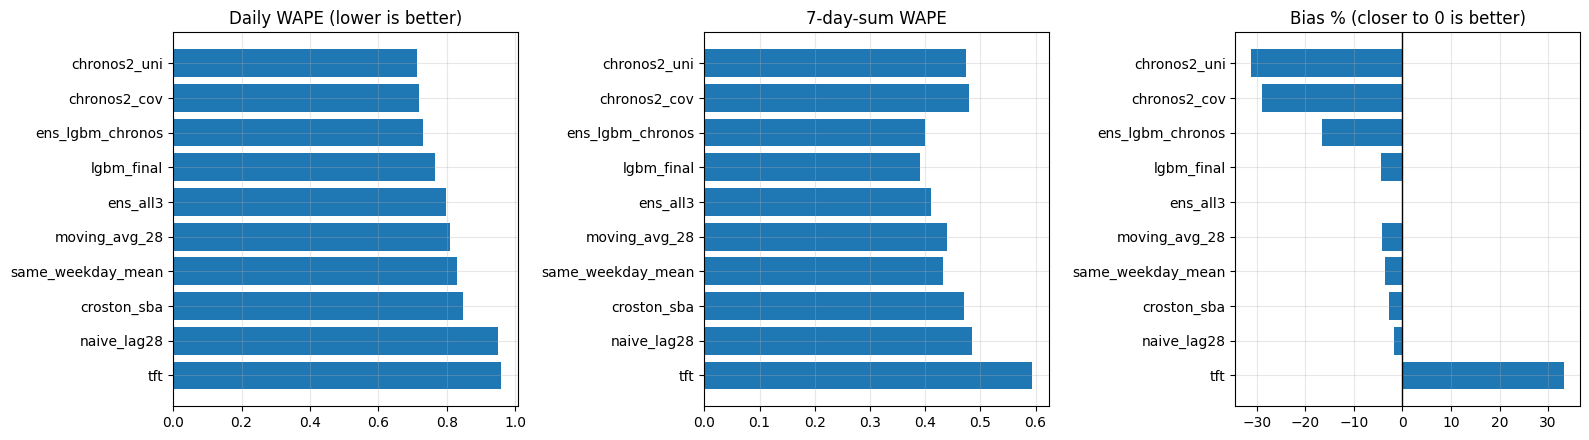

In [14]:
plot_tbl = full_tbl.sort_values("WAPE")
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, col, title in zip(ax, ["WAPE", "WAPE_7d_sum", "bias_%"], ["Daily WAPE (lower is better)", "7-day-sum WAPE", "Bias % (closer to 0 is better)"]):
    a.barh(plot_tbl.index, plot_tbl[col])
    a.set_title(title); a.invert_yaxis()
    if col == "bias_%":
        a.axvline(0, color="black", lw=1)
plt.tight_layout(); plt.show()

**Results (3-fold average).**

| Model | Daily WAPE | MASE | 7d-sum WAPE | 28d-sum WAPE | Bias |
|---|---|---|---|---|---|
| Moving average 28 | 0.808 | 0.953 | 0.439 | 0.322 | -4.2% |
| **LightGBM** | 0.766 | 0.935 | **0.391** | **0.278** | -4.4% |
| Chronos-2 (univariate) | **0.712** | **0.799** | 0.474 | 0.414 | **-31.2%** |
| Chronos-2 (covariates) | 0.717 | 0.801 | 0.479 | 0.421 | -28.9% |
| TFT | 0.959 | 1.611 | 0.594 | 0.503 | +33.3% |
| Ensemble LightGBM + Chronos-2 | 0.729 | 0.860 | 0.400 | 0.311 | -16.6% |
| Ensemble of all three | 0.797 | 1.104 | 0.411 | 0.304 | +0.0% |

Chronos-2 has the best daily WAPE and MASE, but it under-forecasts total demand by about 30%. Its 28-day-sum WAPE (0.414) is worse than both the moving average (0.322) and seasonal naive (0.304). A plausible explanation (a hypothesis we did not test) is that daily WAPE and MASE reward forecasts near zero on zero-heavy data and Chronos-2's point forecast behaves like a median. The bias of the all-three ensemble is near zero only because TFT's +33% cancels Chronos-2's -31%; its MASE (1.10) is worse than the moving average's.

### Probabilistic forecasts (Fold 1)

Inventory needs a range, not only a point forecast. We compare pinball loss and the coverage of the P10-P90 interval (target about 80%). Because more than half of the days have zero sales, coverage can look high.

| Model | P10 pinball | P50 pinball | P90 pinball | P90 calibration | P10-P90 coverage |
|---|---|---|---|---|---|
| LightGBM | 0.133 | 0.491 | 0.316 | 88.9% | 82.2% |
| Chronos-2 (uni) | 0.138 | 0.484 | 0.318 | 89.9% | 77.6% |
| Chronos-2 (cov) | 0.142 | 0.492 | 0.321 | 89.1% | 72.9% |
| TFT | 0.180 | 0.622 | 0.358 | 93.7% | 38.3% |

In [15]:
def pinball(y, q, a):
    d = np.asarray(y, float) - np.asarray(q, float)
    return float(np.mean(np.maximum(a * d, (a - 1) * d)))

PROB = {"lgbm": ("q10", "q50", "q90"), "chronos2_uni": ("chronos2_uni_q10", "chronos2_uni_q50", "chronos2_uni_q90"),
        "chronos2_cov": ("chronos2_cov_q10", "chronos2_cov_q50", "chronos2_cov_q90"), "tft": ("tft_q10", "tft_q50", "tft_q90")}
rows = []
f1 = ev[ev["fold"] == 1]
for name, (c10, c50, c90) in PROB.items():
    if c10 in f1 and f1[c10].notna().all():
        y = f1["sales"].to_numpy(float)
        rows.append({"model": name,
                     "pinball_P10": pinball(y, f1[c10], 0.1), "pinball_P50": pinball(y, f1[c50], 0.5), "pinball_P90": pinball(y, f1[c90], 0.9),
                     "P90_calibration_%": float((y <= f1[c90]).mean() * 100),
                     "coverage_P10_P90_%": float(((y >= f1[c10]) & (y <= f1[c90])).mean() * 100),
                     "avg_width": float((f1[c90] - f1[c10]).mean())})
prob_tbl = pd.DataFrame(rows).set_index("model") if rows else pd.DataFrame()
prob_tbl

,pinball_P10,pinball_P50,pinball_P90,P90_calibration_%,coverage_P10_P90_%,avg_width
model,,,,,,
lgbm,0.1333,0.4911,0.3157,88.8992,82.2287,3.0145
chronos2_uni,0.1379,0.4838,0.3182,89.9084,77.5694,2.9801
chronos2_cov,0.1420,0.4916,0.3211,89.0960,72.9423,2.8969
tft,0.1800,0.6215,0.3579,93.6802,38.3231,3.4160


---
## 8. Segment-wise comparison

The overall number hides where each model is strong. We compare WAPE by demand class and by volume tier on Fold 1.

In [16]:
stats = pd.read_parquet(STATS_PATH)
stats["id"] = stats["id"].astype(str)
ev["demand_class"] = ev["id"].map(stats.set_index("id")["demand_class"])

seg_models = [m for m in ["moving_avg_28", "lgbm_final", "chronos2_cov", "tft"] if m in ev.columns and ev.loc[ev["fold"] == 1, m].notna().all()]
seg_out = {}
for by in ["demand_class", "vol_tier"]:
    rows = []
    for k, g in ev[ev["fold"] == 1].groupby(by):
        r = {by: k, "sales_share_%": g["sales"].sum() / ev.loc[ev["fold"] == 1, "sales"].sum() * 100}
        for m in seg_models:
            r[m] = wape(g["sales"], g[m])
        rows.append(r)
    seg_out[by] = pd.DataFrame(rows).set_index(by)
    print(f"\n=== WAPE by {by} (Fold 1) ===")
    display(seg_out[by])


=== WAPE by demand_class (Fold 1) ===


,sales_share_%,moving_avg_28,lgbm_final,chronos2_cov,tft
demand_class,,,,,
erratic,11.9542,0.8051,0.6903,0.7138,0.8209
intermittent,40.0788,0.9542,0.9316,0.8484,1.2651
lumpy,22.0076,0.9462,0.8621,0.7846,1.0665
smooth,25.9594,0.4894,0.4285,0.4404,0.4788



=== WAPE by vol_tier (Fold 1) ===


,sales_share_%,moving_avg_28,lgbm_final,chronos2_cov,tft
vol_tier,,,,,
high,70.6799,0.7139,0.6356,0.6274,0.7350
low,9.0058,1.2323,1.2491,0.9795,2.3799
mid,20.3143,0.9767,0.9605,0.8898,1.1339


---
## 9. Scorecard and decision

Accuracy is not the only criterion for choosing a model in practice:

| Criterion | What we look at |
|---|---|
| Accuracy | daily WAPE, MASE |
| Inventory-relevant accuracy | 7d/28d-sum WAPE and **bias** (under-forecasting raises stock-out risk) |
| Uncertainty | quantile calibration |
| Robustness | consistency across folds; behaviour for new items |
| Speed and cost | training and inference time; GPU needed? |
| Serving | how easily the model can be put behind an API |

The rank table below uses the measured numbers (1 = best).

In [17]:
sc = full_tbl.loc[[m for m in ["lgbm_final", "chronos2_uni", "chronos2_cov", "tft", "moving_avg_28"] + ens_made if m in full_tbl.index]].copy()
rank = pd.DataFrame({
    "rank_WAPE": sc["WAPE"].rank(),
    "rank_7d_WAPE": sc["WAPE_7d_sum"].rank(),
    "rank_28d_WAPE": sc["WAPE_28d_sum"].rank(),
    "rank_MASE": sc["MASE"].rank(),
    "rank_abs_bias": sc["bias_%"].abs().rank(),
})
rank["avg_rank"] = rank.mean(axis=1)

def mean_time(prefix):
    v = [t for (n, f), t in TIMING.items() if n == prefix]
    return float(np.mean(v)) if v else np.nan
rank["sec_per_fold"] = [mean_time(m) if m in ("chronos2_uni", "chronos2_cov", "tft") else np.nan for m in rank.index]
rank = rank.sort_values("avg_rank")
rank

,rank_WAPE,rank_7d_WAPE,rank_28d_WAPE,rank_MASE,rank_abs_bias,avg_rank,sec_per_fold
model,,,,,,,
lgbm_final,4.0000,1.0000,1.0000,4.0000,3.0000,2.6000,NaN
ens_lgbm_chronos,3.0000,2.0000,3.0000,3.0000,4.0000,3.0000,NaN
ens_all3,5.0000,3.0000,2.0000,6.0000,1.0000,3.4000,NaN
chronos2_uni,1.0000,5.0000,5.0000,1.0000,6.0000,3.6000,4.7080
moving_avg_28,6.0000,4.0000,4.0000,5.0000,2.0000,4.2000,NaN
chronos2_cov,2.0000,6.0000,6.0000,2.0000,5.0000,4.2000,36.1352
tft,7.0000,7.0000,7.0000,7.0000,7.0000,7.0000,280.0757


### Decision rule (fixed before looking at the results)

1. A model that does not beat the best baseline (28-day moving average) on **both** daily WAPE **and** 7-day-sum WAPE is eliminated.
2. Among the remaining models, the one with the best 7d/28d-sum WAPE and MASE wins; daily WAPE is a tie-breaker.
3. If two models differ by less than 1-2%, prefer the simpler, cheaper and more explainable one.
4. A winner whose bias is below -8% needs a correction before use in inventory.
5. A foundation-model win would still carry the pretraining-overlap caveat and be confirmed on the final holdout.

### Outcome

- Rule 1 eliminates Chronos-2 (7d-sum WAPE 0.474 / 0.479 versus 0.439 for the moving average) and TFT. LightGBM and the ensembles pass.
- Rule 2 selects **LightGBM** (best 7d-sum and 28d-sum WAPE, MASE 0.935).
- Rule 4: LightGBM's bias is -4.4%, which is acceptable.
- By segment (Fold 1), Chronos-2 is better on sparse series (intermittent 0.848 vs 0.932; low tier 0.980 vs 1.249), consistent with the "near zero" explanation above, while LightGBM is better on smooth and erratic series. Chronos-2 also has the shortest run time (about 5 seconds per fold for the univariate variant), whereas LightGBM trains on CPU and its features can be inspected.

**Chosen model: LightGBM.** Chronos-2 remains an interesting challenger (for example with a bias correction) and is a candidate for future model updates.

---
## 10. Saving

All predictions are saved in one Parquet file so that the inventory simulation (Notebook 6) can use any model's forecasts.

In [18]:
ev.to_parquet(OUT / "preds_all_models_h28.parquet", index=False)
results = {
    "full_table": json.loads(full_tbl.round(5).to_json(orient="index")),
    "rank_table": json.loads(rank.round(3).to_json(orient="index")),
    "prob_table": json.loads(prob_tbl.round(4).to_json(orient="index")) if len(prob_tbl) else {},
    "timing_sec": {f"{n}_fold{f}": round(t, 1) for (n, f), t in TIMING.items()},
    "tft_loss": TFT_LOSS, "tft_steps": TFT_MAX_STEPS, "chronos_error": CHRONOS_ERR, "tft_error": TFT_ERR,
    "eligible_series": {f: len(v) for f, v in ELIG.items()},
}
(OUT / "comparison_results_h28.json").write_text(json.dumps(results, indent=2, default=str))
print("Saved:", sorted(p.name for p in OUT.iterdir() if "all_models" in p.name or "comparison" in p.name))

Saved: ['comparison_results_h28.json', 'preds_all_models_h28.parquet']


---
## Summary of results (machine-readable)

If any model section failed, its error message appears in this output.

In [19]:
def r(x):
    return round(float(x), 4) if pd.notna(x) else None

summary = {
    "gpu": HAS_GPU,
    "eligible_series": {f: len(v) for f, v in ELIG.items()},
    "rows_dropped_%_by_fold": ((1 - n_kept / n_total) * 100).round(2).to_dict(),
    "best_baseline": best_base_name,
    "models_3fold_or_available": {m: {"n_folds": int(full_tbl.loc[m, "n_folds"]),
                                      "WAPE": r(full_tbl.loc[m, "WAPE"]), "WAPE_7d": r(full_tbl.loc[m, "WAPE_7d_sum"]),
                                      "WAPE_28d": r(full_tbl.loc[m, "WAPE_28d_sum"]), "MASE": r(full_tbl.loc[m, "MASE"]),
                                      "bias_%": r(full_tbl.loc[m, "bias_%"]),
                                      "vs_best_baseline_%": r(full_tbl.loc[m, "WAPE_vs_best_baseline_%"]),
                                      "WAPE_by_fold": [r(full_tbl.loc[m, f"WAPE_f{f}"]) for f in (1, 2, 3)]}
                                   for m in full_tbl.index},
    "common_folds": sorted(common),
    "quantiles_fold1": json.loads(prob_tbl.round(4).to_json(orient="index")) if len(prob_tbl) else {},
    "segment_wape_fold1": {by: json.loads(df.round(4).to_json(orient="index")) for by, df in seg_out.items()},
    "avg_rank": json.loads(rank["avg_rank"].round(2).to_json()),
    "timing_sec": {f"{n}_fold{f}": round(t) for (n, f), t in TIMING.items()},
    "tft_loss_used": TFT_LOSS, "tft_steps": TFT_MAX_STEPS,
    "chronos_error": CHRONOS_ERR, "tft_error": TFT_ERR, "chronos_loaded": CHRONOS_OK, "tft_import_ok": TFT_OK,
}
print(json.dumps(summary, indent=2, default=str))

{
  "gpu": true,
  "eligible_series": {
    "1": 998,
    "2": 998,
    "3": 997
  },
  "rows_dropped_%_by_fold": {
    "1": 0.1,
    "2": 0.1,
    "3": 0.16
  },
  "best_baseline": "moving_avg_28",
  "models_3fold_or_available": {
    "naive_lag28": {
      "n_folds": 3,
      "WAPE": 0.9505,
      "WAPE_7d": 0.4841,
      "WAPE_28d": 0.3034,
      "MASE": 1.0804,
      "bias_%": -1.815,
      "vs_best_baseline_%": -17.6153,
      "WAPE_by_fold": [
        0.9633,
        0.9621,
        0.926
      ]
    },
    "moving_avg_28": {
      "n_folds": 3,
      "WAPE": 0.8081,
      "WAPE_7d": 0.4394,
      "WAPE_28d": 0.3215,
      "MASE": 0.953,
      "bias_%": -4.2489,
      "vs_best_baseline_%": 0.0,
      "WAPE_by_fold": [
        0.8139,
        0.826,
        0.7844
      ]
    },
    "same_weekday_mean": {
      "n_folds": 3,
      "WAPE": 0.8309,
      "WAPE_7d": 0.4332,
      "WAPE_28d": 0.3121,
      "MASE": 0.9743,
      "bias_%": -3.5217,
      "vs_best_baseline_%": -2.825,
  